# Exercice 3 — Lire un taux et un score de rachat : incertitude, Brier et calibration

> **VERSION CORRIGÉE** 

## Contexte métier
L'équipe ALM vous demande de **lire de façon critique** deux choses : (1) les taux de rachat par segment présentés dans un reporting — sont-ils fiables ? (2) deux modèles de score de rachat proposés par la data science — lequel utiliser pour projeter des flux ? Règle de la formation : *« un chiffre sans effectif ni intervalle n'est pas un résultat, c'est une anecdote »*.

## Objectifs
- Calculer un taux de rachat par segment avec son **intervalle de confiance** (Wald puis Wilson)
- Vérifier par simulation que l'incertitude décroît en **1/√n** (théorème central limite)
- Montrer qu'une **AUC identique** peut cacher une **calibration** très différente (Brier)
- Construire un tableau de calibration et mesurer l'impact sur un **seuil métier** (p > 0,4)

## Rappels théoriques mobilisés (slides de la session)
- *Échantillonnage et incertitude : la fiabilité d'un taux* — IC, segments rares
- *Probabilités : les lois qui décrivent l'actuariat vie* — espérance, variance, théorème central limite
- *Métriques* — score de Brier vs AUC ; *Calibration : quand une probabilité dit vrai*
- *Quatre erreurs de lecture* — « l'AUC est de 0,9, la proba est fiable » ; « 5 % sur le segment, c'est le taux »

## Mini-dictionnaire & prérequis
| Élément | Signification / usage |
|---|---|
| `p̂ = k / n` | taux observé : `k` rachats parmi `n` contrats |
| IC de Wald à 95 % | p̂ ± 1,96 · √(p̂(1−p̂)/n) |
| IC de Wilson à 95 % | centre = (p̂ + z²/2n)/(1 + z²/n) ; demi-largeur = z·√(p̂(1−p̂)/n + z²/4n²)/(1 + z²/n), avec z = 1,96 |
| Brier | BS = moyenne de (p − y)² ; plus petit = meilleur ; mesure ranking **et** niveau |
| AUC (`roc_auc_score`) | capacité de classement uniquement, aucune information sur le niveau des probabilités |
| Calibration | parmi les contrats notés 0,30, ~30 % doivent racheter |
| `pd.qcut`, `groupby().agg()` | découper en classes de même effectif ; agréger par classe |

In [ ]:
# Outil d'auto-vérification — NE PAS MODIFIER
import numpy as np, pandas as pd, matplotlib.pyplot as plt, hashlib
_resultats = {}
def verifier(nom, condition, indice=""):
    """Évalue `condition` (une fonction sans argument) ; affiche ✅ ou ❌ + indice."""
    try: ok = bool(condition())
    except Exception: ok = False
    _resultats[nom] = ok
    print(("✅ " if ok else "❌ ") + nom + ("" if ok or not indice else "\n    💡 " + indice))
def bilan():
    n, k = len(_resultats), sum(_resultats.values())
    print(f"\n🏁 Score : {k}/{n} vérifications réussies")
    print("   Bravo, exercice terminé !" if k == n and n > 0 else "   Reprenez les ❌ ci-dessus (relancez la cellule concernée puis `bilan()`).")
def _h(s): return hashlib.sha1(s.encode()).hexdigest()[:8]
%matplotlib inline

---
## Partie A — Un taux de rachat sans intervalle est une anecdote

In [2]:
from sklearn.metrics import roc_auc_score
segments = pd.DataFrame({
    "segment": ["Petits encours (< 10 k€)", "Encours moyens", "Gros encours (> 150 k€)"],
    "effectif": [4000, 1200, 40],
    "rachats": [200, 66, 2]})
segments

,segment,effectif,rachats
0,Petits encours (< 10 k€),4000,200
1,Encours moyens,1200,66
2,Gros encours (> 150 k€),40,2


**Q1.** (a) Ajoutez la colonne `taux` = rachats / effectif. (b) Calculez l'intervalle de **Wald** à 95 % (`ic_bas`, `ic_haut`). (c) Que constatez-vous sur la dernière ligne ?

<details><summary>💡 Indice 1</summary>

`segments['taux'] = segments['rachats'] / segments['effectif']`

</details>

<details><summary>💡 Indice 2</summary>

`marge = 1.96 * np.sqrt(taux * (1 - taux) / effectif)` ; `ic_bas = taux - marge`.

</details>

In [3]:
segments["taux"] = segments["rachats"] / segments["effectif"]
marge = 1.96 * np.sqrt(segments["taux"] * (1 - segments["taux"]) / segments["effectif"])
segments["ic_bas"] = segments["taux"] - marge
segments["ic_haut"] = segments["taux"] + marge
segments.round(4)

,segment,effectif,rachats,taux,ic_bas,ic_haut
0,Petits encours (< 10 k€),4000,200,0.050,0.0432,0.0568
1,Encours moyens,1200,66,0.055,0.0421,0.0679
2,Gros encours (> 150 k€),40,2,0.050,-0.0175,0.1175


In [4]:
verifier("Q1a · taux = rachats/effectif", lambda: np.allclose(segments["taux"], [0.05, 0.055, 0.05]))
verifier("Q1b · IC de Wald, segment 1", lambda: np.isclose(segments["ic_bas"][0], 0.043246, atol=1e-4) and np.isclose(segments["ic_haut"][0], 0.056754, atol=1e-4))
verifier("Q1b · IC de Wald, gros encours", lambda: np.isclose(segments["ic_bas"][2], -0.017542, atol=1e-4))

✅ Q1a · taux = rachats/effectif
✅ Q1b · IC de Wald, segment 1
✅ Q1b · IC de Wald, gros encours


**Correction** — Les trois segments affichent ~5 % de rachat, mais pour les gros encours (n = 40) la borne basse de Wald est **négative** : un taux ne peut pas être < 0. L'approximation normale est inadaptée aux petits effectifs et aux événements rares.

**Q1d.** On utilise donc l'intervalle de **Wilson** (formule dans le dictionnaire). Écrivez `ic_wilson(k, n, z=1.96)` qui renvoie `(bas, haut)`, puis calculez `bas_gros, haut_gros = ic_wilson(2, 40)`.

In [5]:
def ic_wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - demi, centre + demi

bas_gros, haut_gros = ic_wilson(2, 40)
print(f"Gros encours : {2/40:.1%} [{bas_gros:.1%} ; {haut_gros:.1%}]")

Gros encours : 5.0% [1.4% ; 16.5%]


In [6]:
verifier("Q1d · Wilson borne basse > 0", lambda: bas_gros > 0)
verifier("Q1d · Wilson ≈ [1,4 % ; 16,5 %]", lambda: np.isclose(bas_gros, 0.01382, atol=1e-3) and np.isclose(haut_gros, 0.165042, atol=1e-3))

✅ Q1d · Wilson borne basse > 0
✅ Q1d · Wilson ≈ [1,4 % ; 16,5 %]


**Correction** — Sur 40 contrats, « 5 % » signifie en réalité *entre ≈ 1,4 % et 16,5 %* : on retrouve le chiffre de la slide *Quatre erreurs de lecture*. Les 4 000 petits contrats donnent une fourchette de ± 0,7 point : même taux affiché, fiabilité radicalement différente.

## Partie B — Pourquoi la taille d'échantillon protège (1/√n)

**Q2.** Pour p = 5 %, simulez 2 000 échantillons de taille n ∈ {40, 400, 4 000} (`rng.binomial(n, p, size=2000) / n`) et calculez l'écart-type empirique des taux estimés → dictionnaire `ecarts_types`. Comparez à la théorie √(p(1−p)/n) → `theorie`.

<details><summary>💡 Indice 1</summary>

`rng = np.random.default_rng(1)` ; pour chaque `n` : `taux_simules = rng.binomial(n, p, size=2000) / n` puis `.std()`.

</details>

In [7]:
rng = np.random.default_rng(1)
p = 0.05
ecarts_types, theorie = {}, {}
for n in [40, 400, 4000]:
    taux_simules = rng.binomial(n, p, size=2000) / n
    ecarts_types[n] = taux_simules.std()
    theorie[n] = np.sqrt(p * (1 - p) / n)
print(pd.DataFrame({"empirique": ecarts_types, "théorique": theorie}).round(4))

      empirique  théorique
40       0.0343     0.0345
400      0.0111     0.0109
4000     0.0034     0.0034


In [8]:
verifier("Q2 · 3 tailles simulées", lambda: set(ecarts_types) == {40, 400, 4000})
verifier("Q2 · empirique ≈ théorique (±10 %)", lambda: all(abs(ecarts_types[n]/theorie[n] - 1) < 0.10 for n in (40, 400, 4000)))
verifier("Q2 · ×100 d'effectif ⇒ incertitude ÷10", lambda: 8 < ecarts_types[40] / ecarts_types[4000] < 12, "√100 = 10")

✅ Q2 · 3 tailles simulées
✅ Q2 · empirique ≈ théorique (±10 %)
✅ Q2 · ×100 d'effectif ⇒ incertitude ÷10


**Correction** — Pour diviser l'incertitude par 10 il faut **100 fois plus** de contrats. D'où la prudence sur les segments rares : en gagner en précision exige des effectifs, pas de la sophistication.

## Partie C — Deux scores de rachat : même AUC, mêmes probabilités ?

La data science propose deux modèles pour une **population à risque** (5 000 contrats). Le modèle A est calibré par construction ; le modèle B a exactement le même classement, mais des probabilités gonflées.

In [9]:
rng = np.random.default_rng(7)
N = 5000
p_vrai = rng.beta(2, 9, N)                 # probabilité « réelle » de rachat
y = rng.binomial(1, p_vrai)                # rachat observé (0/1)
p_A = p_vrai                               # modèle A
p_B = p_vrai ** 0.55                       # modèle B : même ordre, niveaux gonflés
print(f"Taux de rachat observé : {y.mean():.1%} | proba moyenne A : {p_A.mean():.1%} | proba moyenne B : {p_B.mean():.1%}")

Taux de rachat observé : 18.0% | proba moyenne A : 18.3% | proba moyenne B : 37.3%


**Q3.** Calculez `auc_A`, `auc_B` (avec `roc_auc_score`) et `brier_A`, `brier_B` (à la main : `np.mean((p - y)**2)`). Puis répondez : pour **projeter des flux de rachat**, quel modèle choisir ? (`choix_modele` = `"A"` ou `"B"`).

<details><summary>💡 Indice 1</summary>

Le Brier est la moyenne des carrés des écarts entre probabilité prédite et issue 0/1.

</details>

In [10]:
auc_A = roc_auc_score(y, p_A)
auc_B = roc_auc_score(y, p_B)
brier_A = np.mean((p_A - y) ** 2)
brier_B = np.mean((p_B - y) ** 2)
choix_modele = "A"
print(f"AUC  A={auc_A:.4f}  B={auc_B:.4f}\nBrier A={brier_A:.4f}  B={brier_B:.4f}")

AUC  A=0.7068  B=0.7068
Brier A=0.1349  B=0.1735


In [11]:
verifier("Q3 · AUC identiques (même classement)", lambda: np.isclose(auc_A, auc_B, atol=1e-9), "B est une transformation croissante de A")
verifier("Q3 · Brier de A", lambda: np.isclose(brier_A, 0.134935, atol=1e-5))
verifier("Q3 · Brier de B plus mauvais", lambda: brier_B > brier_A and np.isclose(brier_B, 0.173476, atol=1e-5))
verifier("Q3 · choix pour projeter des flux", lambda: choix_modele == "A", "il faut des probabilités calibrées")

✅ Q3 · AUC identiques (même classement)
✅ Q3 · Brier de A
✅ Q3 · Brier de B plus mauvais
✅ Q3 · choix pour projeter des flux


**Correction** — L'AUC ne voit que l'ordre : elle est strictement identique. Le Brier, lui, sanctionne le mauvais niveau de B. *Un bon ranking ne suffit pas à alimenter une projection de flux.*

**Q4 · Tableau de calibration.** Écrivez `table_calibration(p, y, q=5)` : découpez les contrats en `q` classes d'effectif égal selon `p` (`pd.qcut(p, q, labels=False)`) et renvoyez un DataFrame indexé par classe avec `p_moy` (probabilité moyenne), `taux_obs` (taux observé) et `effectif`. Appliquez-la aux deux modèles.

<details><summary>💡 Indice 1</summary>

`df = pd.DataFrame({'p': p, 'y': y}); df['classe'] = pd.qcut(df['p'], q, labels=False)`

</details>

<details><summary>💡 Indice 2</summary>

`df.groupby('classe').agg(p_moy=('p','mean'), taux_obs=('y','mean'), effectif=('y','size'))`

</details>

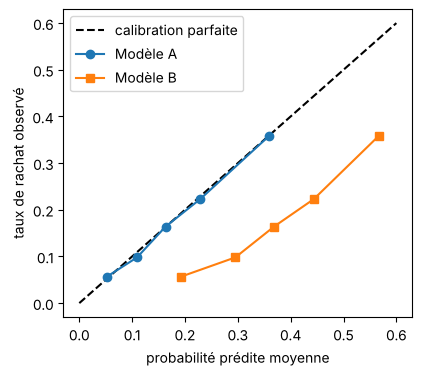

Écart max à la diagonale : A=0.011  B=0.221


,p_moy,taux_obs,effectif
classe,,,
0,0.193,0.057,1000
1,0.295,0.098,1000
2,0.369,0.164,1000
3,0.444,0.223,1000
4,0.566,0.358,1000


In [12]:
def table_calibration(p, y, q=5):
    df = pd.DataFrame({"p": p, "y": y})
    df["classe"] = pd.qcut(df["p"], q, labels=False)
    return df.groupby("classe").agg(p_moy=("p", "mean"), taux_obs=("y", "mean"), effectif=("y", "size"))

tab_A, tab_B = table_calibration(p_A, y), table_calibration(p_B, y)
ecart_A = (tab_A.p_moy - tab_A.taux_obs).abs().max()
ecart_B = (tab_B.p_moy - tab_B.taux_obs).abs().max()
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, .6], [0, .6], "k--", label="calibration parfaite")
ax.plot(tab_A.p_moy, tab_A.taux_obs, "o-", label="Modèle A"); ax.plot(tab_B.p_moy, tab_B.taux_obs, "s-", label="Modèle B")
ax.set_xlabel("probabilité prédite moyenne"); ax.set_ylabel("taux de rachat observé"); ax.legend(); plt.show()
print(f"Écart max à la diagonale : A={ecart_A:.3f}  B={ecart_B:.3f}"); tab_B.round(3)

In [13]:
verifier("Q4 · 5 classes d'effectif égal", lambda: tab_A.shape == (5, 3) and tab_A.effectif.nunique() == 1)
verifier("Q4 · colonnes attendues", lambda: list(tab_A.columns) == ["p_moy", "taux_obs", "effectif"])
verifier("Q4 · A proche de la diagonale, B non", lambda: ecart_A < 0.04 and ecart_B > 2 * ecart_A, "comparez p_moy et taux_obs")

✅ Q4 · 5 classes d'effectif égal
✅ Q4 · colonnes attendues
✅ Q4 · A proche de la diagonale, B non


**Correction** — Les points du modèle A suivent la diagonale ; ceux de B sont très au-dessus de celle-ci côté prédiction : B annonce par exemple ≈ 0,44 là où on observe ≈ 0,22. *Un modèle peut avoir un excellent classement et des probabilités fausses.*

**Q5 · Impact sur un seuil métier.** Une action commerciale est déclenchée si `p > 0,4`. Pour chaque modèle, calculez le nombre de contrats ciblés (`nb_A`, `nb_B`) et le **taux de rachat réellement observé** parmi eux (`taux_reel_A`, `taux_reel_B`).

In [14]:
seuil = 0.4
cible_A, cible_B = p_A > seuil, p_B > seuil
nb_A, nb_B = int(cible_A.sum()), int(cible_B.sum())
taux_reel_A, taux_reel_B = y[cible_A].mean(), y[cible_B].mean()
print(f"A : {nb_A} ciblés, taux réel {taux_reel_A:.1%} | B : {nb_B} ciblés, taux réel {taux_reel_B:.1%}")

A : 244 ciblés, taux réel 48.8% | B : 2057 ciblés, taux réel 28.7%

In [15]:
verifier("Q5 · nombres ciblés", lambda: nb_A == 244 and nb_B == 2057)
verifier("Q5 · B cible beaucoup plus de contrats", lambda: nb_B > 2 * nb_A)
verifier("Q5 · le seuil « 0,4 » n'a pas le même sens", lambda: taux_reel_A > 0.38 and taux_reel_B < 0.38 - 0.05, "comparez au seuil de 40 %")

✅ Q5 · nombres ciblés


✅ Q5 · B cible beaucoup plus de contrats
✅ Q5 · le seuil « 0,4 » n'a pas le même sens


**Correction & lecture actuarielle** — Avec A, les contrats ciblés rachètent effectivement à ≈ 49 % ; avec B, on cible plus de 8 fois plus de contrats (≈ 2 060 contre ≈ 240) dont le taux réel n'est que d'environ 29 %, loin des « > 40 % » affichés. *Une mauvaise calibration ruine un seuil métier même avec un ranking correct.* Réflexe : toujours demander la calibration par période **et** par segment avant de brancher un score sur une décision.

In [16]:
bilan()


🏁 Score : 18/18 vérifications réussies
   Bravo, exercice terminé !
